In [1]:
from functools import partial
from datetime import datetime, timezone
import yaml

import pytz

import matplotlib
import matplotlib.pyplot as plt

from torch import from_numpy
import numpy as np
import optuna
import mlflow

from ml.data import QuantumJumpDataset, add_feature_noise
from ml.tune import objective
from ml.types import LossType, ModelType
from ml.loss import RMSELoss
from ml.eval import compute_test_error

# Set matplotlib to use TeX for rendering
matplotlib.rcParams.update({"font.size": 16}) 
plt.rcParams["figure.dpi"] = 125 # set fig resolution

plt.rcParams.update({"text.usetex": True, "font.family": "Helvetica"})

/home/amanuelant/.local/lib/python3.10/site-packages/pymc_marketing/mlflow.py:185: FutureWarning: This functionality is experimental and subject to change. If you encounter any issues or have suggestions, please raise them at: https://github.com/pymc-labs/pymc-marketing/issues/new
  warnings.warn(warning_msg, FutureWarning, stacklevel=1)
/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/pyfunc/utils/data_validation.py:186: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


In [2]:
with open("single_nn_train.yaml", "r") as file:
    config = yaml.safe_load(file)

Dataset `train_val_data/estimation_data/train/1D/taus.npy` contains $3,200,000$ ($80\%$ of the original training data from the paper) trajectories of length $T=48$ and `deltas.npy` contains $3,200,000$ the associated detuning parameter $\Delta$ for each trajectory.

In [3]:
fraction = config["data"]["fraction"]

train_set_size = int(3_200_000 * fraction)
val_set_size = int(800_000 * fraction)


X_train = np.load("../train_val_data/estimation_data/train/1D/taus.npy")[
    :train_set_size
]

if config["model"] == "deepset":
    # make each element in a trajectory a 1D tensor for deep set network
    X_train = np.expand_dims(X_train, axis=-1)


# NOTE: I use reshape to change the default shape of the 1D labels
# from (N,) to (N,1) to not
# run into broadcast issues with PyTorch loss computation
y_train = np.load("../train_val_data/estimation_data/train/1D/deltas.npy").reshape(
    -1, 1
)[:train_set_size]


X_val = np.load("../train_val_data/estimation_data/val/1D/taus.npy")[:val_set_size]


y_val = np.load("../train_val_data/estimation_data/val/1D/deltas.npy").reshape(-1, 1)[
    :val_set_size
]


print(f"Shape of train data: {X_train.shape}.")
print(f"Shape of train labels: {y_train.shape}.")

print(f"Shape of val data: {X_val.shape}.")
print(f"Shape of val labels: {y_val.shape}.")


train_dataset = QuantumJumpDataset(
    X_train,
    y_train,
    feature_noise_std=config["data"]["feature_noise_std"],
    label_noise_std=config["data"]["label_noise_std"],
    seed=config["data"]["seed"]
)
val_dataset = QuantumJumpDataset(
    X_val,
    y_val,
    feature_noise_std=config["data"]["feature_noise_std"],
    label_noise_std=config["data"]["label_noise_std"],
    seed=config["data"]["seed"]
)

Shape of train data: (32000, 48).
Shape of train labels: (32000, 1).
Shape of val data: (8000, 48).
Shape of val labels: (8000, 1).


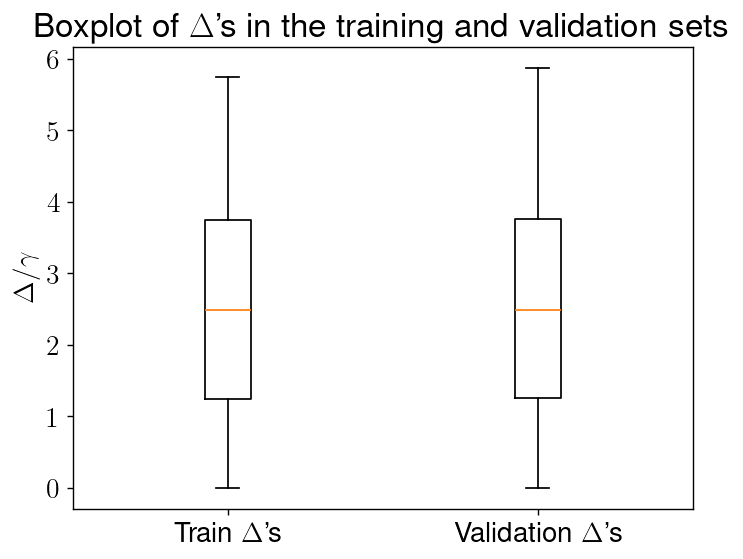

In [4]:
data = [train_dataset.labels.numpy().flatten(), val_dataset.labels.numpy().flatten()]
plt.boxplot(data, tick_labels=[f"Train $\Delta$'s", f"Validation $\Delta$'s"])
plt.ylabel(r"$\Delta/\gamma$")
plt.title("Boxplot of $\Delta$'s in the training and validation sets");

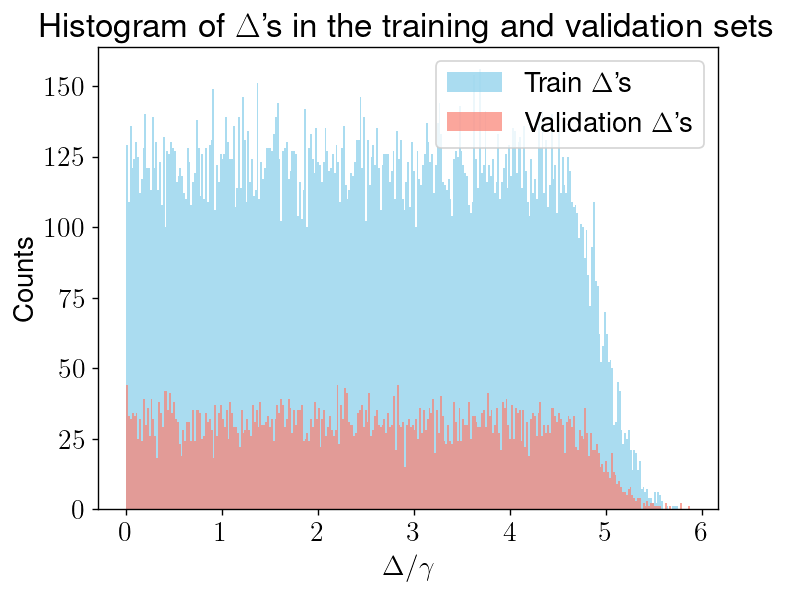

In [5]:
data = [train_dataset.labels.numpy().flatten(), val_dataset.labels.numpy().flatten()]
plt.hist(data[0], bins=300, alpha=0.7, label=f"Train $\Delta$'s", color="skyblue")
plt.hist(data[1], bins=300, alpha=0.7, label=f"Validation $\Delta$'s", color="salmon")
plt.xlabel(r"$\Delta/\gamma$")
plt.ylabel("Counts")
plt.legend()
plt.title("Histogram of $\Delta$'s in the training and validation sets");

In [6]:
model_cls, trainer_cls = ModelType[config["model"]["model_type"]].value

In [ ]:
partial_objective_fn = partial(
    objective,
    model_cls=model_cls,
    trainer_cls=trainer_cls,
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    device=config["model"]["device"],
    objective_metric=config["optuna"]["objective_metric"],
    epochs_per_val=config["epochs_per_val"],
    hidden_layer_sizes=config["model"]["hidden_layer_sizes"]
)

# get current time in UTC
utc_dt = datetime.now(timezone.utc)

# convert to US Eastern Time
est_dt = utc_dt.astimezone(pytz.timezone("US/Eastern"))

# format to 12-hour time with AM/PM
est_str = est_dt.strftime("%B/%d/%Y %I:%M:%S %p")

if config["mlflow"]["use_current_date"]:
    mlflow.set_experiment(f"{config['model']['model_type']} - {est_str} - TLS")
else:
    mlflow.set_experiment("Single Networks - TLS")

Traceback (most recent call last):
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 356, in search_experiments
    exp = self._get_experiment(exp_id, view_type)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 454, in _get_experiment
    meta = FileStore._read_yaml(experiment_dir, FileStore.META_DATA_FILE_NAME)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 1595, in _read_yaml
    return _read_helper(root, file_name, attempts_remaining=retries)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/store/tracking/file_store.py", line 1588, in _read_helper
    result = read_yaml(root, file_name)
  File "/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/utils/yaml_utils.py", line 107, in read_yaml
    raise MissingConfigException(f"Yaml file '{file_path}' does not exist.")
mlflow.exceptions.MissingCon

/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/data/dataset_source_registry.py:149: UserWarning: Failed to determine whether UCVolumeDatasetSource can resolve source information for 'https://zenodo.org/records/8305509'. Exception: 
  return _dataset_source_registry.resolve(
[I 2025-08-26 12:51:33,737] A new study created in memory with name: no-name-a2bde473-8b4a-43c3-8f4c-d3d67214594f


Stopping early at epoch 29/351


[I 2025-08-26 12:53:18,798] Trial 0 finished with value: 4.5676250010728836e-05 and parameters: {'num_bins': 210, 'training_loss_function': 'rmse', 'lr': 0.002306849119628044, 'beta1': 0.81252675750061, 'beta2': 0.8533440133555451, 'num_epochs': 350, 'batch_size': 64, 'dropout': 0.2, 'patience': 7}. Best is trial 0 with value: 4.5676250010728836e-05.


Stopping early at epoch 8/346


[I 2025-08-26 12:53:30,798] Trial 1 finished with value: 0.00038496556878089903 and parameters: {'num_bins': 560, 'training_loss_function': 'msle', 'lr': 0.00023177114140087593, 'beta1': 0.9806634724581071, 'beta2': 0.9879338556208026, 'num_epochs': 345, 'batch_size': 2048, 'dropout': 0.1, 'patience': 7}. Best is trial 0 with value: 4.5676250010728836e-05.


...

[I 2025-08-26 13:10:23,885] Trial 10 finished with value: 4.55750972032547e-05 and parameters: {'num_bins': 440, 'training_loss_function': 'rmse', 'lr': 0.001648192594054095, 'beta1': 0.9122993407923058, 'beta2': 0.9219514606464845, 'num_epochs': 500, 'batch_size': 256, 'dropout': 0.05, 'patience': 10}. Best is trial 4 with value: 4.524840787053108e-05.
[I 2025-08-26 13:10:49,720] Trial 11 pruned. 
[I 2025-08-26 13:11:16,577] Trial 12 pruned. 
[I 2025-08-26 13:11:33,577] Trial 13 pruned. 
[I 2025-08-26 13:12:06,774] Trial 14 pruned. 
[I 2025-08-26 13:12:32,795] Trial 15 pruned. 
[I 2025-08-26 13:12:33,803] Trial 16 pruned. 


Stopping early at epoch 62/386


[I 2025-08-26 13:13:45,827] Trial 17 finished with value: 4.564852267503739e-05 and parameters: {'num_bins': 390, 'training_loss_function': 'rmse', 'lr': 0.0027472501832115567, 'beta1': 0.8068476090862129, 'beta2': 0.805959278974738, 'num_epochs': 385, 'batch_size': 256, 'dropout': 0.0, 'patience': 8}. Best is trial 4 with value: 4.524840787053108e-05.


Stopping early at epoch 64/466


[I 2025-08-26 13:16:35,325] Trial 18 finished with value: 4.562721773982048e-05 and parameters: {'num_bins': 700, 'training_loss_function': 'rmse', 'lr': 0.0014603789265255215, 'beta1': 0.9388292210411638, 'beta2': 0.9420328999618391, 'num_epochs': 465, 'batch_size': 128, 'dropout': 0.05, 'patience': 9}. Best is trial 4 with value: 4.524840787053108e-05.
[I 2025-08-26 13:16:36,389] Trial 19 pruned. 


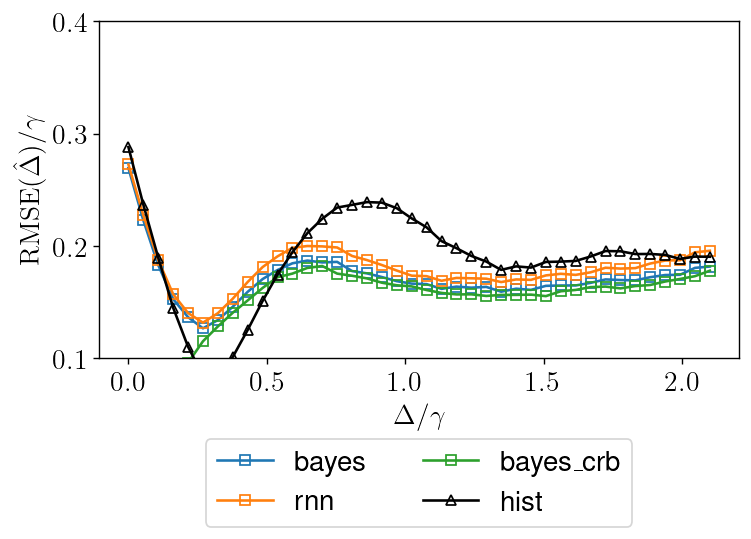

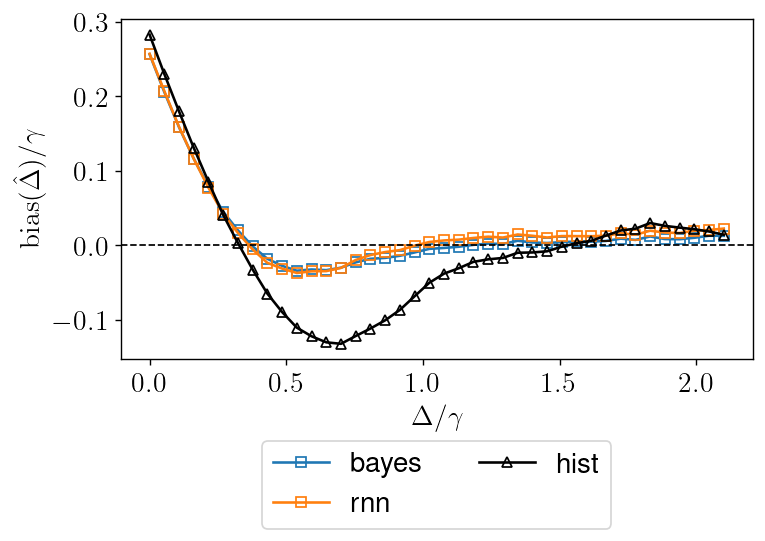

In [8]:
with mlflow.start_run() as parent_run:
    mlflow.log_param("feature_noise_std", config["data"]["feature_noise_std"])
    mlflow.log_param("label_noise_std", config["data"]["label_noise_std"])
    mlflow.log_param("test_set_feature_noise_std", config["data"]["test_set_feature_noise_std"])
    mlflow.log_param("fraction", config["data"]["fraction"])
    mlflow.log_param("seed", config["data"]["seed"])

    # log datasets used for training and validation
    mlflow.log_input(
        mlflow.data.from_numpy(
            features=train_dataset.data.numpy(),
            targets=train_dataset.labels.numpy(),
            name="training_data",
            source="https://zenodo.org/records/8305509",
        ),
        context="training",
    )
    mlflow.log_input(
        mlflow.data.from_numpy(
            features=val_dataset.data.numpy(),
            targets=val_dataset.labels.numpy(),
            name="validation_data ",
            source="https://zenodo.org/records/8305509",
        ),
        context="validation",
    )

    mlflow.log_param("epochs_per_val", config["epochs_per_val"])

    obj_metric = config["optuna"]["objective_metric"]
    lower_is_better = LossType[obj_metric].value[1]

    study = optuna.create_study(
        direction="minimize" if lower_is_better else "maximize",
        pruner=optuna.pruners.MedianPruner(n_startup_trials=10),
    )

    study.optimize(partial_objective_fn, n_trials=config["optuna"]["num_trials"])

    best_trial = study.best_trial
    best_model_uri = f"runs:/{best_trial.user_attrs['run_id']}/torch_model"

    # Log best child run's parameters and objective metric to the parent run
    mlflow.log_params(best_trial.params)
    mlflow.log_param("best_trial_number", best_trial.number)
    mlflow.log_param("best_model_uri", best_model_uri)
    mlflow.log_param("best_model_run_name", best_trial.user_attrs["run_name"])
    mlflow.log_metric(f"best_{config['optuna']['objective_metric']}", best_trial.value)

    device = config["model"]["device"]

    selected_model = mlflow.pytorch.load_model(model_uri=best_model_uri)
    # if model was logged while on gpu it will be loaded back onto gpu and will error out if GPU is not available
    selected_model = selected_model.to(device)

    X_test = np.load(
        "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
    )

    if config['data']['test_set_feature_noise_std'] > 0:
        X_test = add_feature_noise(X_test, config['data']['test_set_feature_noise_std'], config['data']['seed'])
    
    elif config['data']['feature_noise_std'] > 0:
        X_test = add_feature_noise(X_test, config['data']['feature_noise_std'], config['data']['seed'])

    # see above cells for reason for using reshape
    y_test = np.load(
        "../test-trajectories/1D-delta/validation-deltas-1D-delta-nsets-10000.npy"
    ).reshape(-1, 1)

    mlflow.log_input(
        mlflow.data.from_numpy(
            features=X_test,
            targets=y_test,
            name="testing_data",
            source="https://zenodo.org/records/8305509",
        ),
        context="testing",
    )

    X_test = from_numpy(X_test).float().to(device)
    y_test = from_numpy(y_test).float().to(device)

    selected_model.eval()
    rmse_loss = RMSELoss()

    rmses, biases = compute_test_error(selected_model, rmse_loss, X_test, y_test)

    paper_rmses = dict(np.load("../results_cache/carlos_rmses.npz"))
    paper_biases = dict(np.load("../results_cache/carlos_biases.npz"))

    deltalist, _ = paper_rmses.pop("deltalist"), paper_biases.pop("deltalist")
    del paper_rmses["classical"]
    del paper_rmses["classical_crb"]
    #del paper_rmses["bayes_crb"]
    del paper_biases["classical"] 

    fig, ax = plt.subplots()
    for key, value in paper_rmses.items():
        ax.plot(
            deltalist,
            value,
            marker="s",
            markerfacecolor="none",
            linestyle="-",
            label=f"{key}",
        )

    ax.plot(
        y_test.cpu().numpy().flatten(),
        rmses,
        marker="^",
        markerfacecolor="none",
        linestyle="-",
        label=config["model"]["model_type"],
        color="black",
    )

    mlflow.log_metric("mean_test_rmse", np.array(rmses).mean())

    ax.set_xlabel(r"$\Delta/\gamma$")
    ax.set_ylabel(r"$\textrm{RMSE}(\hat{\Delta})/\gamma$")

    ax.set_ylim(0.1, 0.4)
    ax.legend(fancybox=True, bbox_to_anchor=(0.5, -0.2), ncol=2, loc="upper center")
    fig.tight_layout()
    mlflow.log_figure(fig, "rmses.png")

    fig, ax = plt.subplots()
    for key, value in paper_biases.items():
        ax.plot(
            deltalist,
            value,
            marker="s",
            markerfacecolor="none",
            linestyle="-",
            label=f"{key}",
        )

    ax.plot(
        y_test.cpu().numpy().flatten(),
        biases,
        marker="^",
        markerfacecolor="none",
        linestyle="-",
        color="black",
        label=config["model"]["model_type"],
    )
    ax.axhline(
        y=0, color="black", linestyle="--", linewidth=1
    )  # horizontal line at bias = 0

    ax.set_xlabel(r"$\Delta/\gamma$")
    ax.set_ylabel(r"$\textrm{bias}(\hat{\Delta})/\gamma$")
    #ax.set_ylim(-0.1, 0.4)
    ax.legend(fancybox=True, bbox_to_anchor=(0.5, -0.2), ncol=2, loc="upper center")
    fig.tight_layout()
    mlflow.log_figure(fig, "biases.png")


mlflow.end_run()